# Cosmic expansion: four reproducible investigations

Use the **actual Pantheon+ / SH0ES release**, not generated observations. Clone [the repository](https://github.com/Biswajit1999/cosmic-expansion-lab), install `requirements.txt`, and open this notebook inside that checkout. The raw table and covariance are downloaded from a pinned commit and checked against SHA-256 hashes.

The figures and numerical summaries below were executed with the checked-in analysis modules. This is a study of released standardized SN and compressed Cepheid-host distances, not a refit of raw photometry.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
from IPython.display import display, Image
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "analysis/fit.py").exists()), None)
if root is None:
    raise RuntimeError("Open this notebook inside the cloned cosmic-expansion-lab repository.")
sys.path.insert(0, str(root / "analysis"))
from fit import load, fit
from research import fit_variant, sn_only, profile_grid
from cosmology import distance_modulus, luminosity_distance
data, covariance = load()
print(f"{len(data)} light curves; {len(set(data['CID']))} distinct literal CID strings")
print(f"Covariance shape: {covariance.shape}")

All input checksums verified.


1701 light curves; 1543 distinct literal CID strings
Covariance shape: (1701, 1701)


## 1. Recover the calibrated expansion rate

For calibrators, the model uses the released Cepheid-host distance modulus. Other objects use a flat matter+Λ luminosity distance. The residual vector is whitened with a Cholesky factor of the complete selected covariance. H₀, M_B and Ωₘ are fitted jointly.

H0 = 73.533 ± 1.017 km/s/Mpc
Omega_m = 0.3318 ± 0.0180
chi² / dof = 1452.02 / 1654


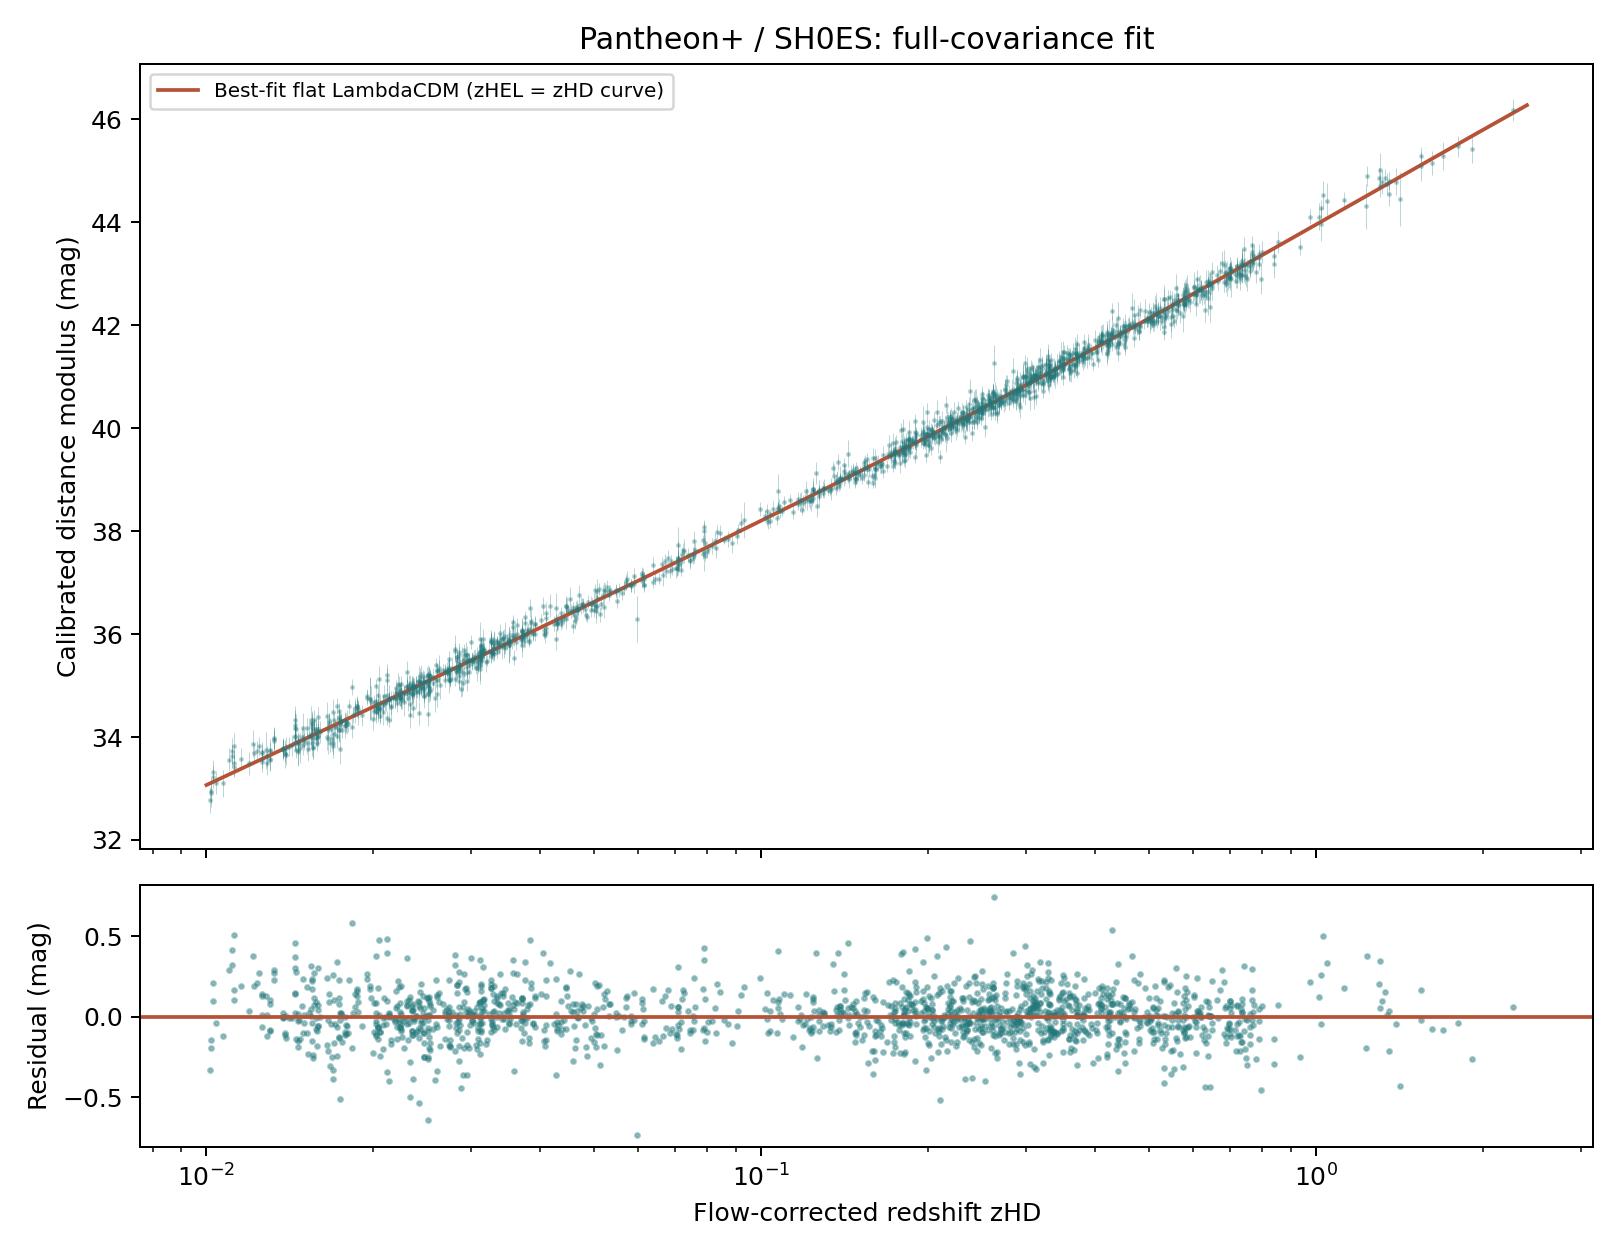

In [2]:
baseline = fit_variant(data, covariance)
print(f"H0 = {baseline['h0']:.3f} ± {baseline['h0_error']:.3f} km/s/Mpc")
print(f"Omega_m = {baseline['omega_m']:.4f} ± {baseline['omega_m_error']:.4f}")
print(f"chi² / dof = {baseline['chi2']:.2f} / {baseline['dof']}")
display(Image(filename=str(root / "results/hubble-diagram.png")))

## 2. Remove the absolute calibration

Supernova brightnesses constrain the **shape** of the distance–redshift relation. Without absolute calibration, H₀ and the brightness offset are degenerate. The code fixes H₀=70 only to define the nuisance offset. It intentionally reports no H₀ measurement.

**Exercise:** prove that changing H₀ shifts every predicted distance modulus by the same amount, −5 log₁₀(H₀,new/H₀,old).

In [3]:
uncalibrated = sn_only(data, covariance)
print(uncalibrated)
z = np.array([0.02, 0.1, 0.5, 1., 2.])
shift = distance_modulus(z, 75) - distance_modulus(z, 70)
np.testing.assert_allclose(shift, -5*np.log10(75/70))
print("Absolute-scale degeneracy verified at five redshifts.")

{'omega_m': 0.33260186716322615, 'omega_m_error': 0.018173123599603425, 'chi2': 1386.4052667825501, 'rows': 1580, 'dof': 1578, 'nuisance_offset_at_h0_70': -19.351406637120057, 'h0': None, 'explanation': 'H0 is unidentifiable without an absolute calibration. H0=70 is a gauge for the nuisance offset, not a measurement.'}
Absolute-scale degeneracy verified at five redshifts.


## 3. Change one sample-selection choice

Repeat the full-covariance fit with zHD thresholds 0.01, 0.023 and 0.05, retaining all calibrators. A higher cut removes more nearby flow objects, where peculiar motions matter most. These samples overlap and share calibration; their error bars are **correlated**, so do not average the results as independent measurements.

z > 0.010: 1657 rows; H0 = 73.533 ± 1.017
z > 0.023: 1448 rows; H0 = 73.694 ± 1.026
z > 0.050: 1133 rows; H0 = 73.594 ± 1.063


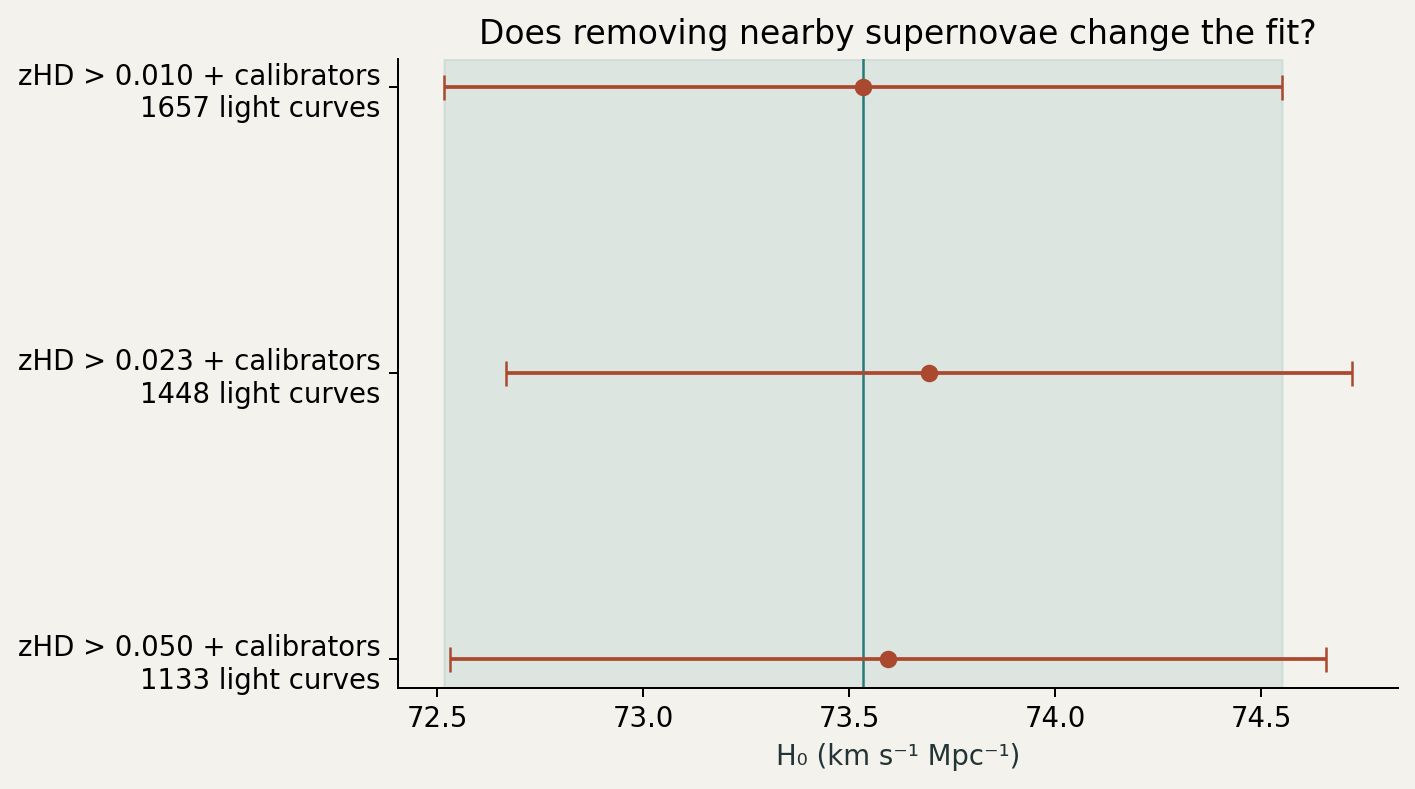

In [4]:
sensitivity = [baseline] + [fit_variant(data, covariance, zmin=zmin) for zmin in (0.023, 0.05)]
for item in sensitivity:
    print(f"z > {item['zmin']:.3f}: {item['rows']} rows; H0 = {item['h0']:.3f} ± {item['h0_error']:.3f}")
display(Image(filename=str(root / "results/redshift-sensitivity.png")))

## 4. Give dark energy one extra degree of freedom

The constant-w extension replaces a constant vacuum density by a component proportional to (1+z)^[3(1+w)]. We fit H₀, M_B, Ωₘ and w. Compare AIC=χ²+2k only for fits using exactly the same rows. A smaller χ² alone is not evidence for new physics, and AIC is not a detection significance.

w = -0.912 ± 0.149 (local Gaussian)
Delta chi² = -0.325
Delta AIC (wCDM - LCDM) = 1.675


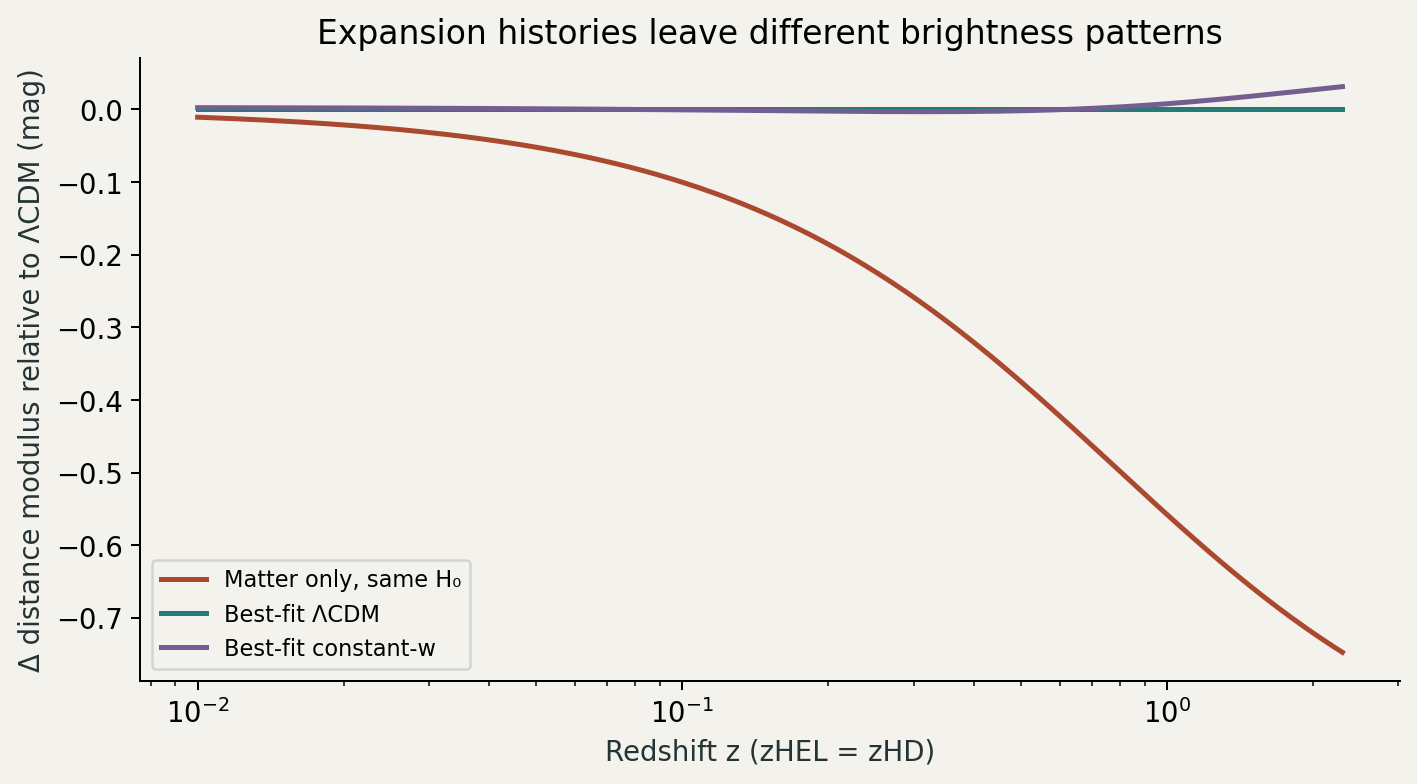

In [5]:
extended = fit_variant(data, covariance, free_w=True)
print(f"w = {extended['w']:.3f} ± {extended['w_error']:.3f} (local Gaussian)")
print(f"Delta chi² = {extended['chi2']-baseline['chi2']:.3f}")
print(f"Delta AIC (wCDM - LCDM) = {extended['aic']-baseline['aic']:.3f}")
display(Image(filename=str(root / "results/model-comparison.png")))

## The likelihood landscape

For each (H₀, Ωₘ), profile the absolute magnitude analytically. The contour thresholds Δχ²=2.30 and 6.18 are approximate joint 68.3% and 95.4% confidence regions for **two** parameters. They are not one-dimensional 1σ and 2σ error bars and are not posterior probabilities.

Profile grid: 57 × 65
Minimum sampled delta chi²: 0.0011


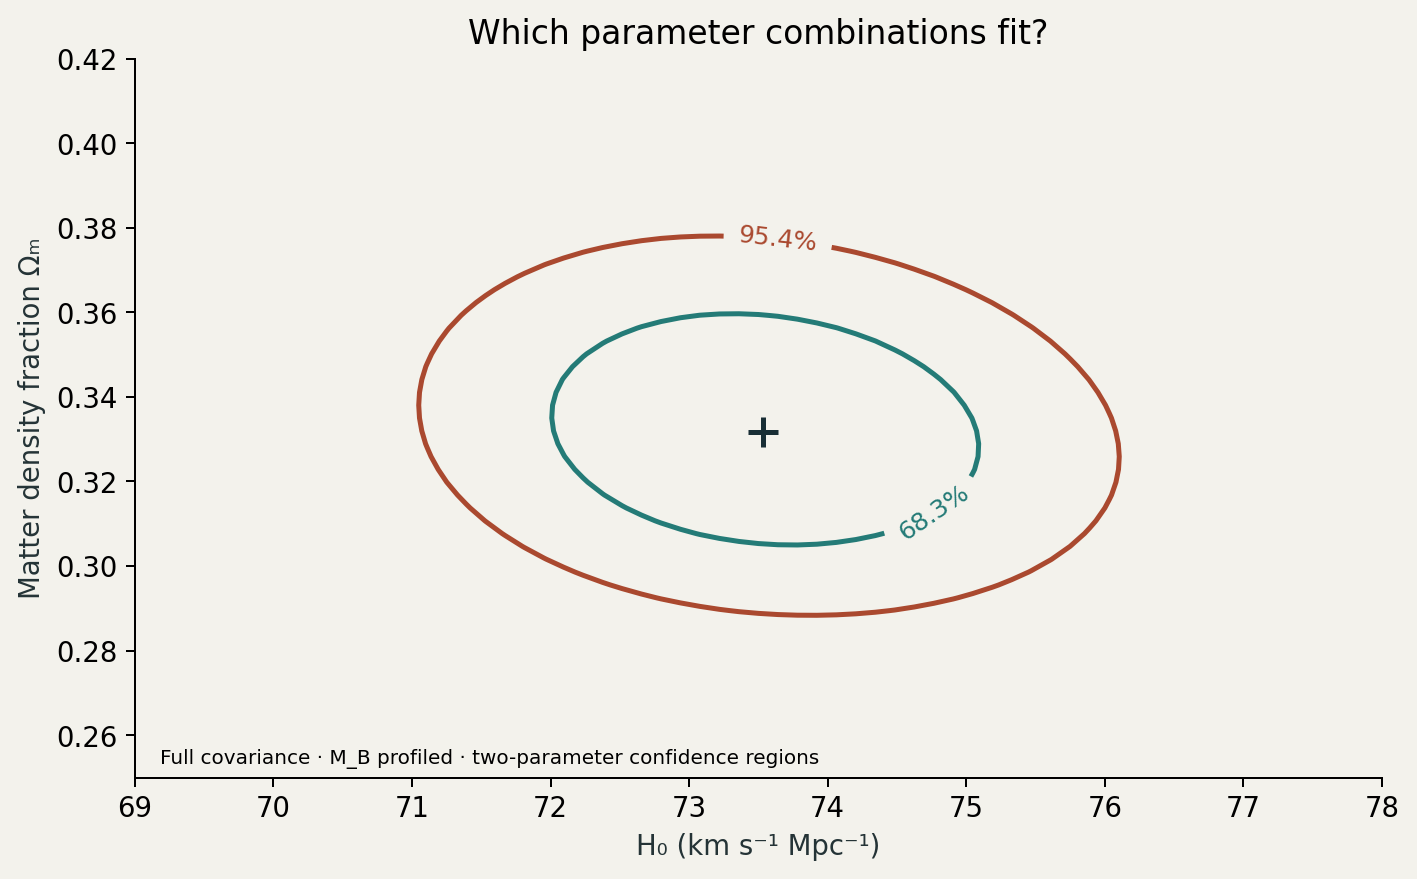

In [6]:
grid = profile_grid(data, covariance, baseline)
print(f"Profile grid: {len(grid['omega_m'])} × {len(grid['h0'])}")
print(f"Minimum sampled delta chi²: {np.min(grid['delta_chi2']):.4f}")
display(Image(filename=str(root / "results/likelihood-contours.png")))

## Interpret the result before quoting it

- A fitted parameter belongs to a model, sample selection and calibration scheme.
- Local Gaussian errors are useful approximations, not a replacement for posterior exploration.
- Repeated light curves remain separate rows with correlated uncertainty.
- The published SH0ES and Planck numbers in the website are dated references, not independent datasets fitted in this notebook.
- No raw spectrum, raw Cepheid light curve, BAO catalog or gravitational-wave event is fitted here.

**Further investigations:** inspect residuals by survey; fit a different justified redshift threshold; add a physically motivated prior and document how it changes the question. Do not discard correlations or invent independent data points.

Sources: [data release](https://github.com/PantheonPlusSH0ES/DataRelease), [Pantheon+](https://arxiv.org/abs/2202.04077), [SH0ES](https://arxiv.org/abs/2112.04510).